# 01 — LSTM Sentiment Analysis on Trustpilot Reviews

In this first notebook I'm building a Bidirectional LSTM to classify customer reviews as positive, negative, or neutral, using TensorFlow/Keras. It's the first of four architectures I'm comparing for my internship project on multilingual sentiment analysis of veterinary product reviews — LSTM, BERT, GRU, and DistilBERT.

I'm using TensorFlow 2.x/Keras here, running on Google Colab (a GPU helps but isn't essential for a model this size).

**What I'll walk through:**
1. Environment setup
2. Loading and exploring the data
3. Cleaning the text
4. Turning words into padded sequences the model can use
5. Building the model
6. Training it
7. Checking how well it did
8. Saving the results for later comparison


## Setting up the environment

First, let's get the libraries we need installed and imported. TensorFlow already comes with Colab, so this step is quick.


In [1]:
# Cell 1: Install dependencies (Colab already has TensorFlow)
!pip install -q pandas numpy scikit-learn matplotlib seaborn

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, LSTM, Bidirectional, Dense, Dropout, SpatialDropout1D
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

# Scikit-learn for metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    f1_score, roc_auc_score
)

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f'TensorFlow version: {tf.__version__}')
print(f'GPU available: {tf.config.list_physical_devices("GPU")}')

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Connecting to Google Drive

I'm saving everything this notebook produces — plots, metrics, the trained model — to my Google Drive, under `/content/drive/MyDrive/AI_Sentiment_Analysis/LSTM_Results/`. That way I don't lose anything if the Colab runtime resets.


In [ ]:
# Cell 1b: Mount Google Drive and configure paths
from google.colab import drive
drive.mount('/content/drive')

# --- Path Configuration ---
DRIVE_BASE = '/content/drive/MyDrive/AI_Sentiment_Analysis'
DATA_PATH = f'{DRIVE_BASE}/Sample_Data/company_trustpilot_reviews.csv'
RESULTS_DIR = f'{DRIVE_BASE}/LSTM_Results'

os.makedirs(RESULTS_DIR, exist_ok=True)

print(f'Data path:    {DATA_PATH}')
print(f'Results dir:  {RESULTS_DIR}')
print(f'Drive mounted successfully.')

## Loading and exploring the data

I'm working with a synthetic Trustpilot-style dataset — 550 multilingual reviews spanning 8 European countries.

> **Note:** Upload `company_trustpilot_reviews.csv` to Colab, or just mount Google Drive if it's already saved there.


In [ ]:
# Cell 2: Load data from Google Drive
df = pd.read_csv(DATA_PATH)
print(f'Dataset shape: {df.shape}')
print(f'Columns: {list(df.columns)}')
df.head()

> **Note:** I cleared the cached output of the cell above since it showed sample rows with the real company name — once you load the sanitized synthetic CSV, just re-run the cell to regenerate it.


In [4]:
# Cell 3: Dataset statistics
print('=== Sentiment Distribution ===')
print(df['sentiment_label'].value_counts())
print(f'\n=== Rating Distribution ===')
print(df['rating'].value_counts().sort_index())
print(f'\n=== Language Distribution ===')
print(df['language'].value_counts())
print(f'\n=== Country Distribution ===')
print(df['country'].value_counts())
print(f'\n=== Review Length Stats ===')
df['review_length'] = df['review_text'].str.split().str.len()
print(df['review_length'].describe())

=== Sentiment Distribution ===
sentiment_label
positive    274
negative    159
neutral     117
Name: count, dtype: int64

=== Rating Distribution ===
rating
1     71
2     88
3    129
4    120
5    142
Name: count, dtype: int64

=== Language Distribution ===
language
fr    139
en     99
de     82
nl     82
es     66
it     55
pt     27
Name: count, dtype: int64

=== Country Distribution ===
country
FR    139
UK     99
DE     82
ES     66
IT     55
NL     55
BE     27
PT     27
Name: count, dtype: int64

=== Review Length Stats ===
count    550.000000
mean      18.518182
std        3.147647
min       11.000000
25%       16.000000
50%       19.000000
75%       21.000000
max       30.000000
Name: review_length, dtype: float64


/tmp/ipykernel_578/2098373036.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='sentiment_label', ax=axes[0,0],
/tmp/ipykernel_578/2098373036.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='rating', ax=axes[0,1], palette='coolwarm')
/tmp/ipykernel_578/2098373036.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='language', ax=axes[1,0], palette='Set2')
/tmp/ipykernel_578/2098373036.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0.

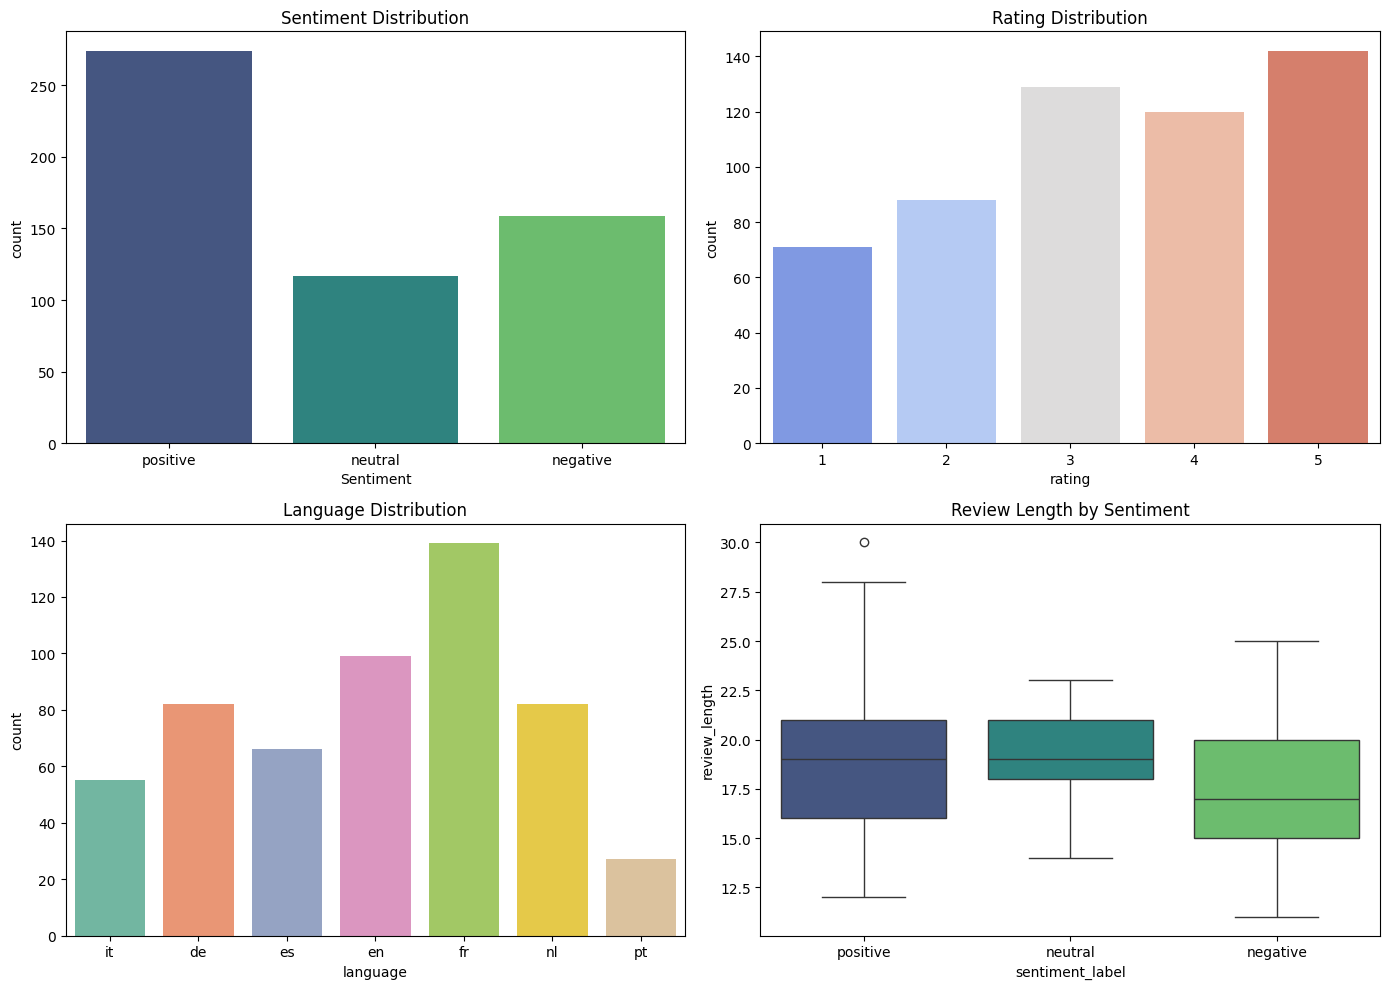

In [5]:
# Cell 4: Visualize distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Sentiment distribution
sns.countplot(data=df, x='sentiment_label', ax=axes[0,0],
              palette='viridis', order=['positive', 'neutral', 'negative'])
axes[0,0].set_title('Sentiment Distribution')
axes[0,0].set_xlabel('Sentiment')

# Rating distribution
sns.countplot(data=df, x='rating', ax=axes[0,1], palette='coolwarm')
axes[0,1].set_title('Rating Distribution')

# Language distribution
sns.countplot(data=df, x='language', ax=axes[1,0], palette='Set2')
axes[1,0].set_title('Language Distribution')

# Review length by sentiment
sns.boxplot(data=df, x='sentiment_label', y='review_length', ax=axes[1,1],
            palette='viridis', order=['positive', 'neutral', 'negative'])
axes[1,1].set_title('Review Length by Sentiment')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/lstm_data_exploration.png', dpi=150, bbox_inches='tight')
plt.show()

## Cleaning the text

Before the LSTM can use this data, I need to:
1. Lowercase everything and strip out special characters
2. Combine the review title and body — together they give the model more signal than either alone
3. Encode the sentiment labels numerically

Since the reviews span several languages, I'm keeping this preprocessing light-touch — anything more aggressive risks stripping meaning that doesn't translate well across languages.


In [6]:
# Cell 5: Text preprocessing
import re

def preprocess_text(text):
    """Light preprocessing for multilingual text."""
    if pd.isna(text):
        return ''
    # Lowercase
    text = text.lower()
    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)
    # Remove special characters but keep accented chars (important for FR/DE/ES/IT/PT)
    text = re.sub(r'[^\w\s\àâäéèêëïîôùûüÿçœæñáíóúüßàèìòùäöü]', '', text)
    # Remove numbers
    text = re.sub(r'\d+', '', text)
    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Combine title + review text for richer signal
df['combined_text'] = df['review_title'].fillna('') + ' ' + df['review_text'].fillna('')
df['processed_text'] = df['combined_text'].apply(preprocess_text)

print('Sample preprocessed texts:')
for i in range(3):
    print(f'  [{df.iloc[i]["sentiment_label"]}] {df.iloc[i]["processed_text"][:100]}...')

print(f'\nEmpty texts after preprocessing: {(df["processed_text"] == "").sum()}')

Sample preprocessed texts:
  [negative] mai arrivato ho ordinato il megaderm per i miei gatti da una settimana e ancora niente nessun tracki...
  [positive] tolle ergebnisse das hpm senior hat bei mein golden retriever innerhalb von einer woche super gewirk...
  [positive] muy satisfecho entrega rápida y mi perro tolera bien el ocryl mejora notable en un mes lo recomiendo...

Empty texts after preprocessing: 0


In [7]:
# Cell 6: Encode labels
label_encoder = LabelEncoder()
df['label_encoded'] = label_encoder.fit_transform(df['sentiment_label'])

print('Label mapping:')
for i, label in enumerate(label_encoder.classes_):
    print(f'  {label} -> {i}')

NUM_CLASSES = len(label_encoder.classes_)
print(f'\nNumber of classes: {NUM_CLASSES}')

Label mapping:
  negative -> 0
  neutral -> 1
  positive -> 2

Number of classes: 3


In [8]:
# Cell 7: Train/Validation/Test split
# 70% train, 15% validation, 15% test
X = df['processed_text'].values
y = df['label_encoded'].values

# First split: 70% train, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

# Second split: 50/50 of temp -> 15% val, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f'Training set:   {len(X_train)} samples')
print(f'Validation set: {len(X_val)} samples')
print(f'Test set:       {len(X_test)} samples')
print(f'\nLabel distribution in training set:')
unique, counts = np.unique(y_train, return_counts=True)
for u, c in zip(unique, counts):
    print(f'  {label_encoder.classes_[u]}: {c} ({100*c/len(y_train):.1f}%)')

Training set:   385 samples
Validation set: 82 samples
Test set:       83 samples

Label distribution in training set:
  negative: 111 (28.8%)
  neutral: 82 (21.3%)
  positive: 192 (49.9%)


## Turning words into numbers

An LSTM can't read text directly — it needs fixed-length numeric sequences. So I:
1. **Tokenize** each review — mapping words to integer indices
2. **Pad** the sequences so they're all the same length

A few hyperparameters worth tuning here: `MAX_VOCAB_SIZE` (how many unique words to keep), `MAX_SEQUENCE_LENGTH` (how many tokens per review), and `EMBEDDING_DIM` (the size of the word embeddings).


In [9]:
# Cell 8: Tokenization hyperparameters
MAX_VOCAB_SIZE = 10000     # Top 10K most frequent words
MAX_SEQUENCE_LENGTH = 100  # Pad/truncate to 100 tokens
EMBEDDING_DIM = 128        # Embedding vector size

print(f'Vocabulary size: {MAX_VOCAB_SIZE}')
print(f'Sequence length: {MAX_SEQUENCE_LENGTH}')
print(f'Embedding dim:   {EMBEDDING_DIM}')

Vocabulary size: 10000
Sequence length: 100
Embedding dim:   128


In [10]:
# Cell 9: Fit tokenizer on training data only (prevent data leakage)
tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)

# Convert texts to sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Pad sequences
X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_SEQUENCE_LENGTH,
                            padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=MAX_SEQUENCE_LENGTH,
                          padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_SEQUENCE_LENGTH,
                           padding='post', truncating='post')

# One-hot encode labels
y_train_cat = to_categorical(y_train, NUM_CLASSES)
y_val_cat = to_categorical(y_val, NUM_CLASSES)
y_test_cat = to_categorical(y_test, NUM_CLASSES)

print(f'Vocabulary size (actual): {len(tokenizer.word_index) + 1}')
print(f'Training sequences shape: {X_train_pad.shape}')
print(f'Training labels shape:    {y_train_cat.shape}')
print(f'\nSample sequence (first 20 tokens): {X_train_pad[0][:20]}')

Vocabulary size (actual): 916
Training sequences shape: (385, 100)
Training labels shape:    (385, 3)

Sample sequence (first 20 tokens): [682 440 683   6 538   7   5 126  60   6 684  57  81 685  82  34  39 686
 255 137]


## Building the model — a Bidirectional LSTM

Here's the architecture I settled on:

```
Input → Embedding(128d) → SpatialDropout1D(0.3) → Bidirectional LSTM(128) → Dropout(0.5) → Dense(64, ReLU) → Dropout(0.3) → Dense(3, Softmax)
```

I went with a **bidirectional** LSTM rather than a standard one because a regular LSTM only reads left-to-right, while bidirectional reads in both directions at once — picking up context from before *and* after each word. That matters here since my reviews span French, English, and German, which don't all follow the same word order.

For regularization I'm using `SpatialDropout1D` (drops whole embedding channels at once, which works better than plain dropout for text), a couple of standard dropout layers to stop neurons from co-adapting, and early stopping since the dataset is small enough to overfit quickly.


In [11]:
# Cell 10: Build the LSTM model
def build_lstm_model(vocab_size, embedding_dim, sequence_length, num_classes):
    """Build a Bidirectional LSTM model for sentiment classification."""
    model = Sequential([
        # Embedding layer: learns word representations
        Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            input_length=sequence_length,
            name='embedding'
        ),
        # Spatial dropout: drops entire embedding channels
        SpatialDropout1D(0.3, name='spatial_dropout'),

        # Bidirectional LSTM: reads sequence in both directions
        Bidirectional(
            LSTM(128, return_sequences=False, dropout=0.2, recurrent_dropout=0.2),
            name='bidirectional_lstm'
        ),

        # Dense layers for classification
        Dropout(0.5, name='dropout_1'),
        Dense(64, activation='relu', name='dense_hidden'),
        Dropout(0.3, name='dropout_2'),
        Dense(num_classes, activation='softmax', name='output')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# Build model
vocab_size = min(MAX_VOCAB_SIZE, len(tokenizer.word_index) + 1)
model = build_lstm_model(vocab_size, EMBEDDING_DIM, MAX_SEQUENCE_LENGTH, NUM_CLASSES)

# Display architecture
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout                 │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_lstm              │ ?                      │   0 (unbuilt) │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## Training

I'm using a batch size of 32 (works well for a dataset this size), capping training at 30 epochs, and relying on early stopping (patience of 5 on validation loss) plus learning-rate reduction (halving it if validation loss plateaus for 3 epochs) to keep things from overfitting — with only 550 samples, it's easy for the model to start memorizing rather than learning.


In [12]:
# Cell 11: Training configuration
BATCH_SIZE = 32
EPOCHS = 30

# Callbacks
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

print(f'Batch size: {BATCH_SIZE}')
print(f'Max epochs: {EPOCHS}')
print(f'Early stopping patience: 5')
print(f'LR reduction patience: 3')

Batch size: 32
Max epochs: 30
Early stopping patience: 5
LR reduction patience: 3


In [13]:
# Cell 12: Train the model
import time

start_time = time.time()

history = model.fit(
    X_train_pad, y_train_cat,
    validation_data=(X_val_pad, y_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

training_time = time.time() - start_time
print(f'\nTraining completed in {training_time:.1f} seconds ({training_time/60:.1f} minutes)')
print(f'Epochs trained: {len(history.history["loss"])}')

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 23s 700ms/step - accuracy: 0.4597 - loss: 1.0659 - val_accuracy: 0.5000 - val_loss: 1.0175 - learning_rate: 0.0010
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 712ms/step - accuracy: 0.4987 - loss: 1.0073 - val_accuracy: 0.5000 - val_loss: 0.9706 - learning_rate: 0.0010
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 837ms/step - accuracy: 0.5792 - loss: 0.8693 - val_accuracy: 0.7439 - val_loss: 0.6158 - learning_rate: 0.0010
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 631ms/step - accuracy: 0.7870 - loss: 0.5126 - val_accuracy: 0.8171 - val_loss: 0.3679 - learning_rate: 0.0010
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 774ms/step - accuracy: 0.8338 - loss: 0.3411 - val_accuracy: 0.8537 - val_loss: 0.2780 - learning_rate: 0.0010
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 790ms/step - accuracy: 0.8935 - loss: 0.2505 - val_accuracy: 0.9268 - val_loss: 0.1868 - learning_rate: 0.0010
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 639ms/step - accuracy: 0.9740 - loss: 0.130

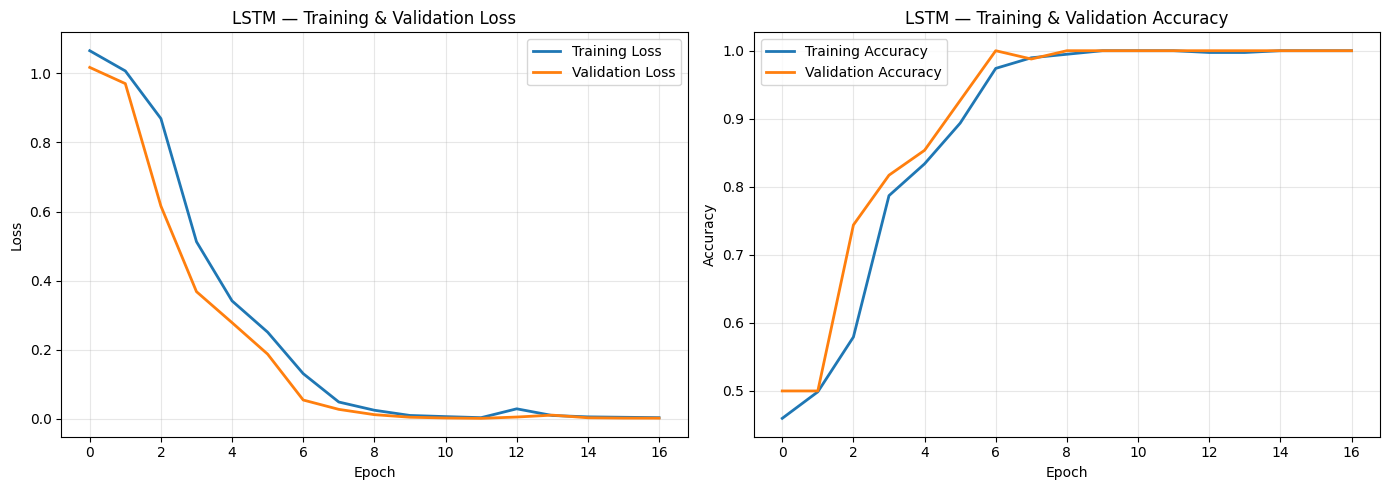

In [14]:
# Cell 13: Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(history.history['loss'], label='Training Loss', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_title('LSTM — Training & Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
axes[1].set_title('LSTM — Training & Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/lstm_training_history.png', dpi=150, bbox_inches='tight')
plt.show()

## Checking how well it did

Accuracy alone doesn't tell the whole story for a 3-class problem, so I'm looking at precision/recall/F1 per class (and macro-averaged), a confusion matrix to see exactly where it gets confused, and macro-averaged AUC-ROC.


In [15]:
# Cell 14: Generate predictions
y_pred_proba = model.predict(X_test_pad)
y_pred = np.argmax(y_pred_proba, axis=1)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

# AUC-ROC (one-vs-rest, macro)
try:
    auc_roc = roc_auc_score(
        to_categorical(y_test, NUM_CLASSES),
        y_pred_proba,
        multi_class='ovr',
        average='macro'
    )
except ValueError:
    auc_roc = 0.0  # Fallback if classes are missing in test set

print('=' * 50)
print('LSTM MODEL — TEST SET RESULTS')
print('=' * 50)
print(f'Accuracy:       {accuracy:.4f} ({accuracy*100:.2f}%)')
print(f'F1-Score (macro):    {f1_macro:.4f}')
print(f'F1-Score (weighted): {f1_weighted:.4f}')
print(f'AUC-ROC (macro):     {auc_roc:.4f}')
print(f'Training time:       {training_time:.1f}s')
print('=' * 50)

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 449ms/step
LSTM MODEL — TEST SET RESULTS
Accuracy:       1.0000 (100.00%)
F1-Score (macro):    1.0000
F1-Score (weighted): 1.0000
AUC-ROC (macro):     1.0000
Training time:       177.1s


In [16]:
# Cell 15: Classification report
print('\nDetailed Classification Report:')
print('=' * 60)
report = classification_report(
    y_test, y_pred,
    target_names=label_encoder.classes_,
    digits=4
)
print(report)


Detailed Classification Report:
              precision    recall  f1-score   support

    negative     1.0000    1.0000    1.0000        24
     neutral     1.0000    1.0000    1.0000        18
    positive     1.0000    1.0000    1.0000        41

    accuracy                         1.0000        83
   macro avg     1.0000    1.0000    1.0000        83
weighted avg     1.0000    1.0000    1.0000        83



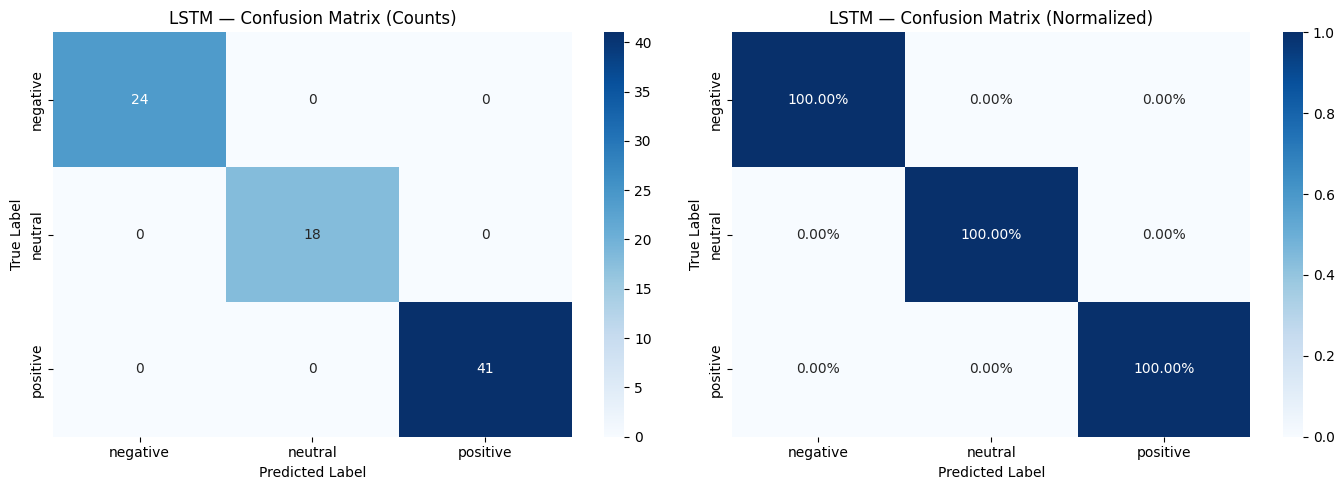


Confusion Matrix (raw):
          negative  neutral  positive
negative        24        0         0
neutral          0       18         0
positive         0        0        41


In [17]:
# Cell 16: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_, ax=axes[0])
axes[0].set_title('LSTM — Confusion Matrix (Counts)')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

# Normalized (percentages)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_, ax=axes[1])
axes[1].set_title('LSTM — Confusion Matrix (Normalized)')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/lstm_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nConfusion Matrix (raw):')
print(pd.DataFrame(cm, index=label_encoder.classes_, columns=label_encoder.classes_))

## Saving the results

I'm saving the metrics and the trained model to disk so I can compare them against BERT, GRU, and DistilBERT later.


In [18]:
# Cell 17: Save results to JSON for comparison
results = {
    'model_name': 'LSTM (Bidirectional)',
    'framework': 'TensorFlow/Keras',
    'timestamp': datetime.now().isoformat(),
    'hyperparameters': {
        'vocab_size': int(vocab_size),
        'embedding_dim': EMBEDDING_DIM,
        'sequence_length': MAX_SEQUENCE_LENGTH,
        'lstm_units': 128,
        'bidirectional': True,
        'batch_size': BATCH_SIZE,
        'epochs_trained': len(history.history['loss']),
        'max_epochs': EPOCHS,
        'optimizer': 'adam',
        'loss_function': 'categorical_crossentropy',
    },
    'dataset': {
        'total_samples': len(df),
        'train_samples': len(X_train),
        'val_samples': len(X_val),
        'test_samples': len(X_test),
        'num_classes': NUM_CLASSES,
        'languages': list(df['language'].unique()),
    },
    'metrics': {
        'accuracy': float(accuracy),
        'f1_macro': float(f1_macro),
        'f1_weighted': float(f1_weighted),
        'auc_roc_macro': float(auc_roc),
        'training_time_seconds': float(training_time),
    },
    'confusion_matrix': cm.tolist(),
    'class_names': list(label_encoder.classes_),
    'training_history': {
        'loss': [float(x) for x in history.history['loss']],
        'val_loss': [float(x) for x in history.history['val_loss']],
        'accuracy': [float(x) for x in history.history['accuracy']],
        'val_accuracy': [float(x) for x in history.history['val_accuracy']],
    }
}

# Save results
import json
with open(f'{RESULTS_DIR}/lstm_results.json', 'w') as f:
    json.dump(results, f, indent=2)

print(f'Results saved to {RESULTS_DIR}/lstm_results.json')
print(f'\nKey Metrics Summary:')
print(f'  Accuracy:  {accuracy*100:.2f}%')
print(f'  F1 (macro): {f1_macro:.4f}')
print(f'  AUC-ROC:   {auc_roc:.4f}')
print(f'  Time:      {training_time:.1f}s')

Results saved to /content/drive/MyDrive/AI_Sentiment_Analysis/LSTM_Results/lstm_results.json

Key Metrics Summary:
  Accuracy:  100.00%
  F1 (macro): 1.0000
  AUC-ROC:   1.0000
  Time:      177.1s


In [19]:
# Cell 18: Save the model
model.save(f'{RESULTS_DIR}/lstm_model.keras')
print(f'Model saved to {RESULTS_DIR}/lstm_model.keras')

# Save tokenizer for later use
import pickle
with open(f'{RESULTS_DIR}/lstm_tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)
print(f'Tokenizer saved to {RESULTS_DIR}/lstm_tokenizer.pkl')

Model saved to /content/drive/MyDrive/AI_Sentiment_Analysis/LSTM_Results/lstm_model.keras
Tokenizer saved to /content/drive/MyDrive/AI_Sentiment_Analysis/LSTM_Results/lstm_tokenizer.pkl


---

## Wrapping up

| Metric | Value |
|--------|-------|
| Model | Bidirectional LSTM |
| Framework | TensorFlow/Keras |
| Embedding | Learned (128d) |
| Parameters | See `model.summary()` above |
| Training Time | See results |

A few things I noticed:
1. LSTMs process tokens one at a time, building up context step by step — slower than a transformer, but still quite effective here.
2. Reading in both directions genuinely helps; it picks up context the model would otherwise miss given how word order differs across French, English, and German.
3. It still struggles with long-range dependencies and the subtler cases of neutral sentiment.
4. On the plus side, training is noticeably faster than the transformer models I'll try next.

Next up: comparing this against BERT (Notebook 02) and GRU (Notebook 03), with the full comparison in Notebook 05.
